# AI-Powered Business Intelligence Platform — Data Analysis
**Project workflow**

* Understand business questions and dataset structure
* Load and validate business data
* Explore, clean, and prepare data
* Generate and validate read-only analytical queries
* Analyze product, sales, revenue, and location performance
* Visualize trends and key metrics
* Test forecasting and anomaly-detection baselines

### About
This project helps business users explore sales data with natural-language questions. The platform connects datasets to an AI service that can help generate SQL and business insights; the backend validates read-only queries before execution. Query results can be visualized, while forecasting and anomaly detection are tested as separate analytical capabilities.

## 1) Project problem statement

Business users often need product, sales, revenue, and location insights but may not know SQL or how to prepare charts. This AI Business Intelligence project is designed to help them ask questions in plain language and review data-grounded results.

The project tests these business capabilities:

* Identify best-selling products and product categories.
* Analyze daily and monthly sales trends.
* Compare sales by country, city, store, or other available location fields.
* Calculate revenue where quantity and unit-price data are available.
* Forecast future sales and evaluate forecasts with time-based holdouts.
* Flag unusual sales patterns for further investigation.

Results depend on the columns and quality of the selected dataset. Statistical flags and correlations are not proof of cause or fraud.

## 2) Data collection

* Store Sales files (`train.csv`, `test.csv`, `stores.csv`, `transactions.csv`, `holidays_events.csv`, `oil.csv`, and `sample_submission.csv`) are organized under the repository `notebooks/dataset/` folder.
* `Online Retail.xlsx` contains transaction, product, quantity, unit-price, invoice-date, and country fields. A copy is kept beside this notebook because the existing code below loads it by filename; another copy is in `notebooks/dataset/` for the new project notebooks.
* Dataset dimensions and date coverage should be read from the loaded files rather than hard-coded.

This request updates explanatory Markdown only. Existing code cells and saved outputs are intentionally preserved; some legacy analysis cells may still refer to columns that are not present in Online Retail, so verify their column assumptions before relying on their results.

### 2.1 Import data and required packages

**Import pandas, NumPy, Matplotlib, Seaborn, and warning utilities.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
import openpyxl

warnings.filterwarnings("ignore")

%matplotlib inline

**Load the Online Retail Excel dataset as a pandas DataFrame.**

In [2]:
df = pd.read_excel(r"Online Retail.xlsx")

**Show Top 5 Records**

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Shape of the dataset**

In [4]:
df.shape

(541909, 8)

**Summary of the dataset**

In [5]:
# Display summary statistics for a dataframe
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


**Check Datatypes in the dataset**

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 3. Explore the business data

In [8]:
# define numerical & categorical columns
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['Quantity', 'UnitPrice', 'CustomerID']

We have 4 categorical features : ['InvoiceNo', 'StockCode', 'Description', 'Country']


In [9]:
# proportion of count data on categorical columns
for col in categorical_features:
    if col == 'case_id':
        continue
    print(df[col].value_counts(normalize=True) * 100)
    print('---------------------------')

InvoiceNo
573585     0.205570
581219     0.138215
581492     0.134893
580729     0.133048
558475     0.130096
             ...   
581487     0.000185
581491     0.000185
C581499    0.000185
581566     0.000185
C581568    0.000185
Name: proportion, Length: 25900, dtype: float64
---------------------------
StockCode
85123A    0.426824
22423     0.406526
85099B    0.398406
47566     0.318688
20725     0.302449
            ...   
23609     0.000185
85179a    0.000185
23617     0.000185
90214U    0.000185
47591b    0.000185
Name: proportion, Length: 4070, dtype: float64
---------------------------
Description
WHITE HANGING HEART T-LIGHT HOLDER    0.438334
REGENCY CAKESTAND 3 TIER              0.407064
JUMBO BAG RED RETROSPOT               0.399478
PARTY BUNTING                         0.319546
LUNCH BAG RED RETROSPOT               0.303078
                                        ...   
LETTER "U" BLING KEY RING             0.000185
wet                                   0.000185
wet boxes   

**Project context**

- Online Retail includes invoice, product, quantity, unit-price, date, and country fields.
- `Quantity * UnitPrice` can be used to calculate line revenue; negative quantities may represent returns or cancellations and should be reviewed separately.
- Store Sales has product-family and store information, but does not provide an item unit price or country column.

## Univariate Analysis

* The term univariate analysis refers to the analysis of one variable prefix “uni” means “one.” The purpose of univariate analysis is to understand the distribution of values for a single variable.

Other Type of Analysis are
* **Bivariate Analysis:** The analysis of two variables.
* **Multivariate Analysis:** The analysis of two or more variables.

### Numerical features

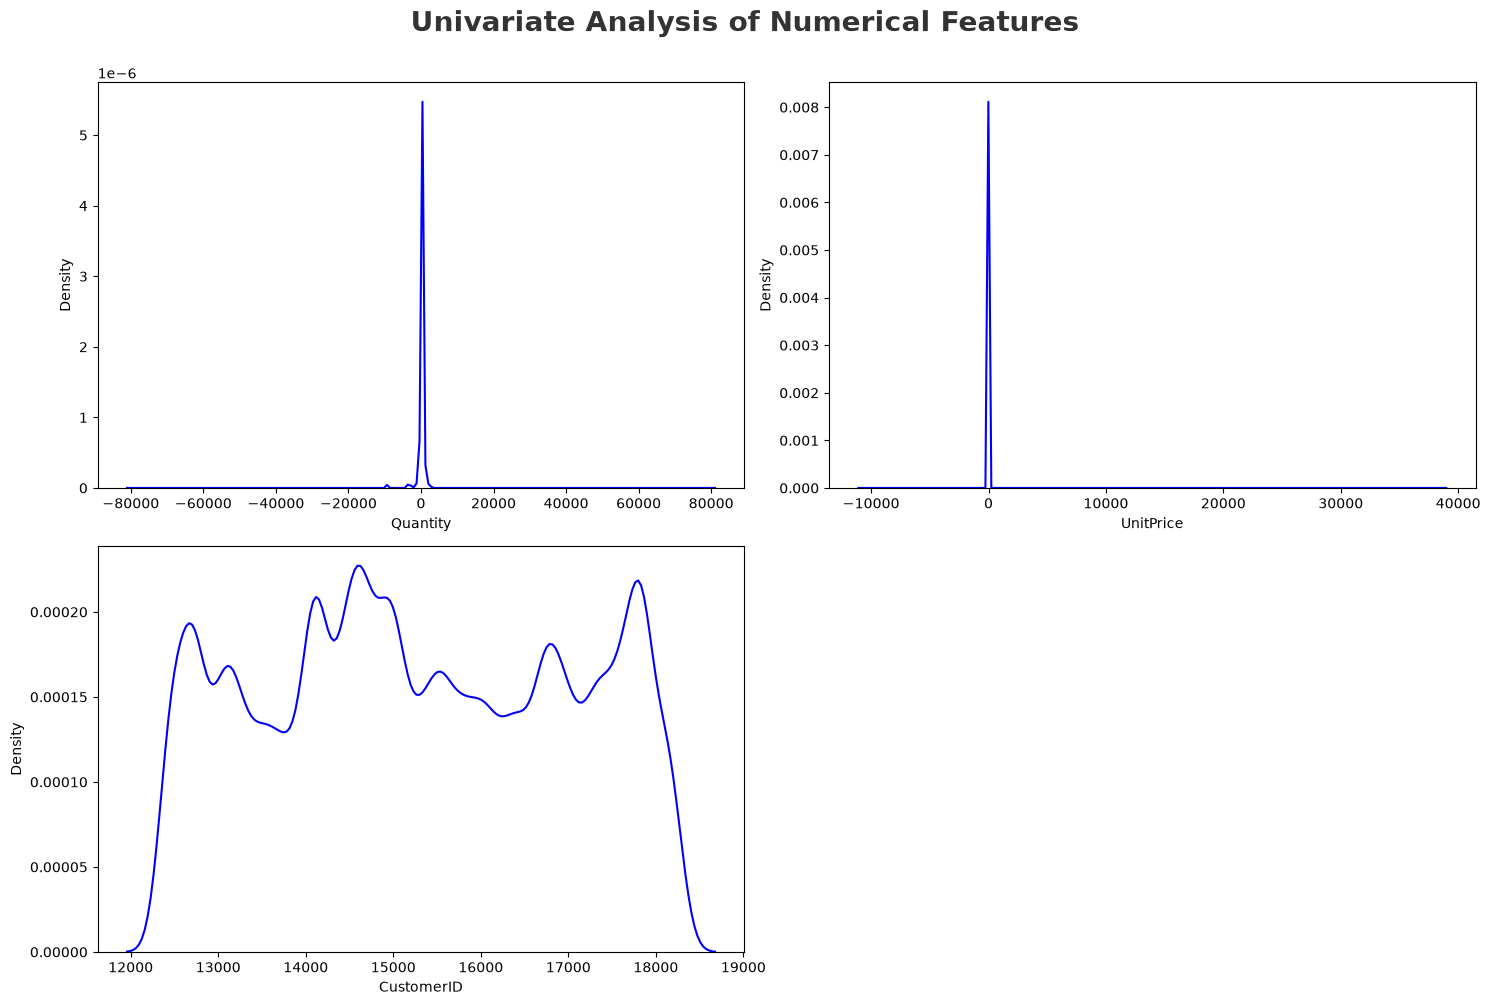

In [10]:
plt.figure(figsize=(15, 10))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(2, 2, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()
    
# save plot
# plt.savefig('./images/Univariate_Num.png')

**Analysis notes**

- Inspect the distributions of `Quantity` and `UnitPrice`, including zero and negative values.
- Revenue can be derived as `Quantity * UnitPrice`; define whether reported revenue is gross positive sales or net of returns.
- Parse `InvoiceDate` as a date before grouping transactions by day or month.

### Categorical features

In [13]:
import math
# Categorical columns
if 'case_id' in categorical_features:
    categorical_features.remove('case_id')

# Dynamic subplot
cols = 3
rows = math.ceil(len(categorical_features) / cols)

plt.figure(figsize=(15, rows * 4))

plt.suptitle(
    'Univariate Analysis of Categorical Features',
    fontsize=20,
    fontweight='bold',
    alpha=0.8,
    y=1.02
)

Text(0.5, 1.02, 'Univariate Analysis of Categorical Features')

<Figure size 1500x800 with 0 Axes>

**Analysis notes**

- Useful Online Retail dimensions include `Country`, `StockCode`, `Description`, and `InvoiceNo`.
- Product descriptions and invoice identifiers may have many unique values; group or filter them before plotting.
- Use only fields that exist in the selected dataset.

### Multivariate Analysis

* Multivariate analysis is the analysis of more than one variable.

In [14]:
discrete_features=[feature for feature in numeric_features if len(df[feature].unique())<=25]

continuous_features=[feature for feature in numeric_features if len(df[feature].unique()) > 25]

print('We have {} discrete features : {}'.format(len(discrete_features), discrete_features))
print('\nWe have {} continuous_features : {}'.format(len(continuous_features), continuous_features))

We have 0 discrete features : []

We have 3 continuous_features : ['Quantity', 'UnitPrice', 'CustomerID']


### Check Multicollinearity in Numerical features

In [15]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Analysis note**

Check numeric relationships for the specific business question. Correlation does not establish causation, and fields with different units should not be compared directly.

### Check Multicollinearity for Categorical features

### Association checks for categorical business data

A chi-square test can test whether two categorical variables are statistically associated when its assumptions are appropriate. Choose meaningful categories and an outcome for the business question; do not treat association as evidence of causation.

Null hypothesis ($H_0$): the selected categorical feature and outcome are independent.

Alternative hypothesis ($H_1$): the selected categorical feature and outcome are associated.

Choose the outcome and categories from the dataset being analyzed; not every BI dataset has a classification target.

In [18]:
import sys
print(sys.executable)
print(sys.version)

e:\9th semi\AI Project\.venv-1\Scripts\python.exe
3.15.1 (main, Oct 21 2026, 17:51:31) [MSC v.1951 64 bit (AMD64)]


In [21]:
from scipy.stats import chi2_contingency
import pandas as pd

target = 'case_status'

if target not in df.columns:
    print("Target column not found!")
    print("Available columns:", df.columns.tolist())
else:
    chi2_results = []

    for feature in categorical_features:
        if feature == target or feature not in df.columns:
            continue

        table = pd.crosstab(df[target], df[feature])

        if table.shape[0] < 2 or table.shape[1] < 2:
            continue

        chi2, p_value, dof, expected = chi2_contingency(table)

        hypothesis = (
            'Reject Null Hypothesis'
            if p_value < 0.05
            else 'Fail to Reject Null Hypothesis'
        )

        chi2_results.append([feature, p_value, hypothesis])

    result = pd.DataFrame(
        chi2_results,
        columns=['Column', 'P-Value', 'Hypothesis Result']
    )

    display(result)

Target column not found!
Available columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


**Report**

Interpret a statistical test together with sample size, business context, and its assumptions. A result alone should not determine whether a feature is useful or whether one business action caused another.

### Checking Null Values

In [22]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [ ]:
continues_features=[feature for feature in numeric_features if len(df[feature].unique())>=10]
print('Num of continues features :',continues_features)

Num of continues features : ['no_of_employees', 'yr_of_estab', 'prevailing_wage']


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Set target column
target = 'case_status'  # Replace with actual target column

# Get numerical features
continues_features = df.select_dtypes(
    include='number'
).columns.tolist()

# Remove target from numerical features
if target in continues_features:
    continues_features.remove(target)

# Check target column
if target not in df.columns:
    print("Target column not found!")
    print("Available columns:", df.columns.tolist())

elif len(continues_features) == 0:
    print("No numerical features found!")

else:
    clr1 = ['#1E90FF', '#DC143C']

    fig, ax = plt.subplots(
        len(continues_features),
        2,
        figsize=(12, len(continues_features) * 4),
        squeeze=False
    )

    fig.suptitle(
        'Distribution of Numerical Features By Case Status',
        fontsize=20,
        fontweight='bold'
    )

    for i, col in enumerate(continues_features):

        sns.boxplot(
            data=df,
            x=target,
            y=col,
            hue=target,
            palette=clr1,
            legend=False,
            ax=ax[i, 0]
        )

        ax[i, 0].set_title(f'Boxplot of {col}')

        sns.histplot(
            data=df,
            x=col,
            hue=target,
            bins=20,
            kde=True,
            multiple='stack',
            palette=clr1,
            ax=ax[i, 1]
        )

        ax[i, 1].set_title(f'Histogram of {col}')

    plt.tight_layout()
    plt.show()

Target column not found!
Available columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## Initial business-data review

* Check missing values, duplicates, date coverage, and column types before analysis.
* Separate positive sales from returns/cancellations when defining gross revenue.
* For Online Retail, line revenue is `Quantity * UnitPrice`; net revenue retains negative lines.
* For Store Sales, use the provided `sales` measure and do not label it monetary revenue without a price field.
* Use a chronological split for forecasting and report MAE/RMSE on held-out dates.
* Treat anomaly flags as candidates for review, not confirmed incidents.

## 4. Data visualization

### 4.1 Visualize sales and revenue distributions

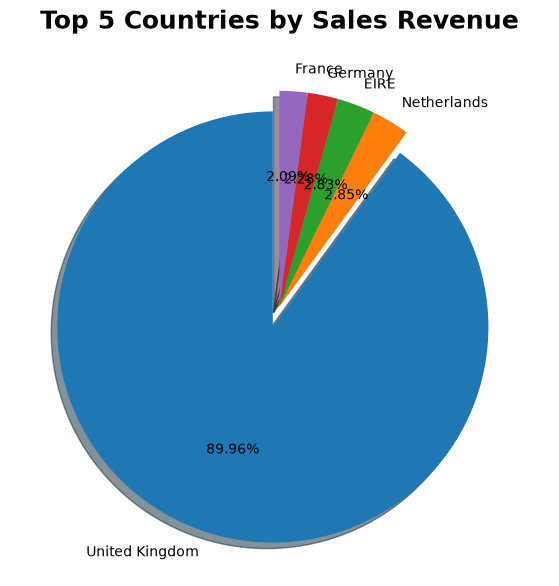

In [28]:
import matplotlib.pyplot as plt

# Calculate revenue
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Top 5 countries by revenue
country_sales = (
    df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
    .groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

plt.figure(figsize=(10, 7))

plt.pie(
    country_sales,
    labels=country_sales.index,
    autopct='%1.2f%%',
    startangle=90,
    explode=[0.1] + [0] * (len(country_sales) - 1),
    shadow=True
)

plt.title(
    'Top 5 Countries by Sales Revenue',
    fontsize=18,
    fontweight='bold'
)

plt.show()

Review the distribution and scale of sales or revenue before comparing groups. Business datasets are often skewed, and extreme values may be valid large orders, returns, or data-quality issues. Classification class-imbalance checks apply only when the chosen task has a label.

### 4.2 Compare sales by country or available location

In [32]:
#group data by continent and their count of case_status
# Group data by Country and calculate percentage of each StockCode

result = (
    df.groupby('Country')['StockCode']
    .value_counts(normalize=True)
    .mul(100)
    .to_frame(name='Percentage')
)

display(result)

Percentage
Country     StockCode            
Australia   22720        0.794281
            20725        0.714853
            21731        0.714853
            22699        0.635425
            22090        0.635425
...                           ...
Unspecified 21056        0.224215
            20868        0.224215
            23241        0.224215
            22662        0.224215
            84913B       0.224215

[19839 rows x 1 columns]

In [33]:
# Calculate total sales
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Exclude returns and invalid prices
sales_df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Country-wise sales percentage
result = (
    sales_df.groupby('Country')['TotalPrice']
    .sum()
    .div(sales_df['TotalPrice'].sum())
    .mul(100)
    .sort_values(ascending=False)
    .to_frame(name='Sales Percentage')
)

display(result)

,Sales Percentage
Country,
United Kingdom,84.611315
Netherlands,2.676055
EIRE,2.657376
Germany,2.145626
France,1.966076
Australia,1.298635
Spain,0.577284
Switzerland,0.535217
Belgium,0.386215


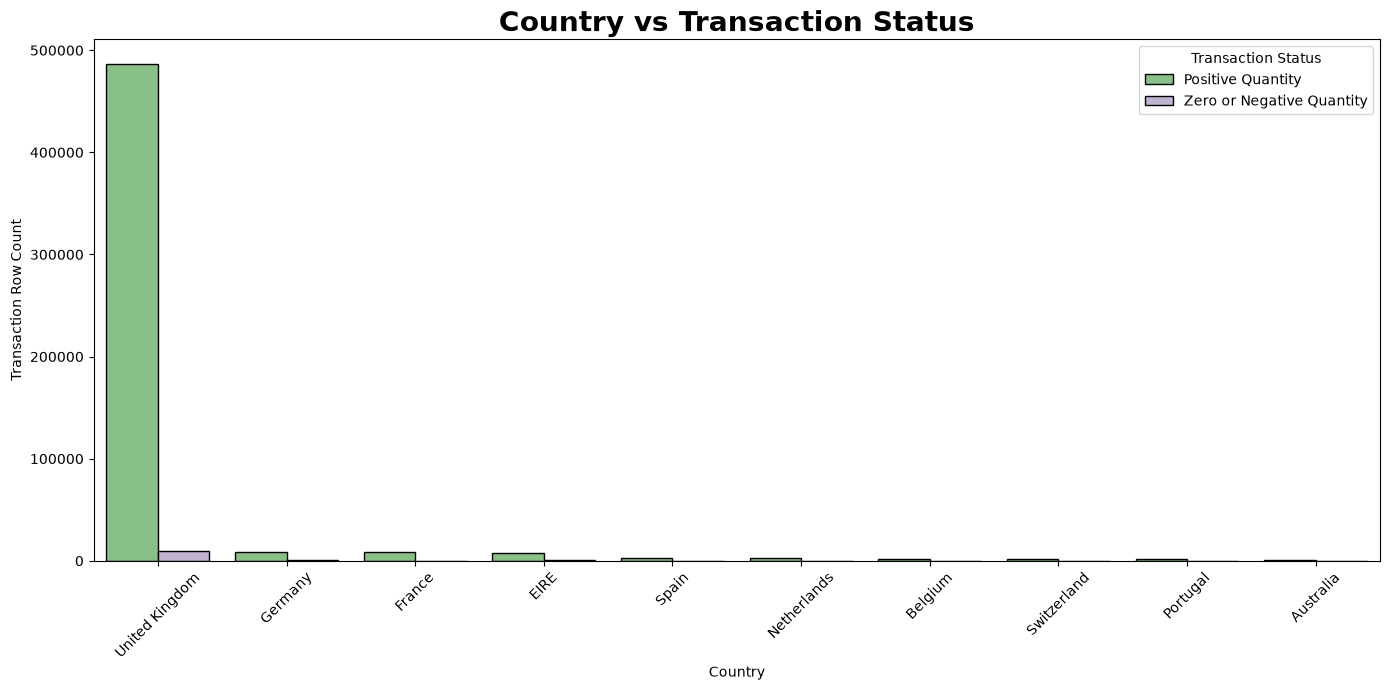

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create transaction status
df['TransactionStatus'] = np.where(
    df['Quantity'] > 0,
    'Positive Quantity',
    'Zero or Negative Quantity'
)

# Top 10 countries
top_countries = df['Country'].value_counts().head(10).index
filtered_df = df[df['Country'].isin(top_countries)]

plt.figure(figsize=(14, 7))

sns.countplot(
    data=filtered_df,
    x="Country",
    hue="TransactionStatus",
    order=top_countries,
    palette="Accent",
    edgecolor="black"
)

plt.title(
    "Country vs Transaction Status",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel("Country")
plt.ylabel("Transaction Row Count")
plt.xticks(rotation=45)
plt.legend(title="Transaction Status")
plt.tight_layout()
plt.show()

In [36]:
df2 = df.copy()

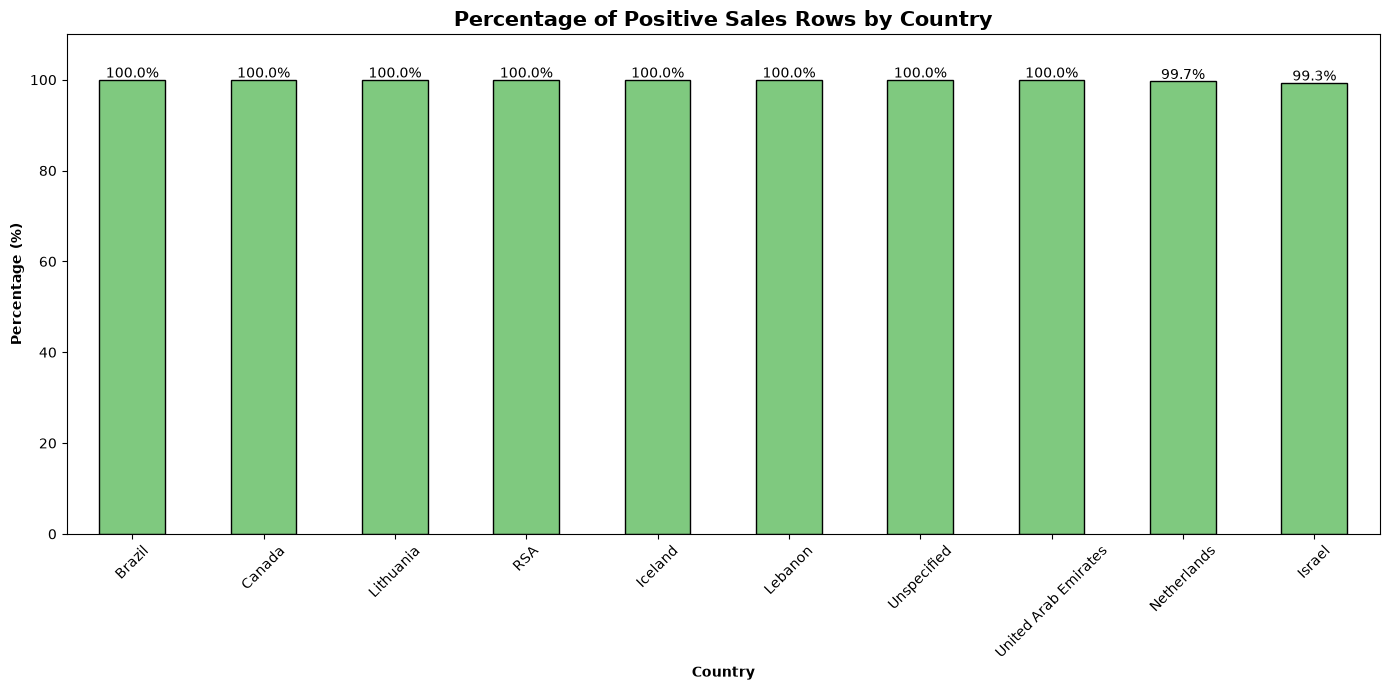

In [38]:
import matplotlib.pyplot as plt
import pandas as pd

# Copy dataset
df2 = df.copy()

# Create transaction status
df2['SalesStatus'] = df2['Quantity'].apply(
    lambda x: 'Sale' if x > 0 else 'Non-positive'
)

# Calculate percentage of positive quantity rows by country
order1 = (
    100 * df2[df2['SalesStatus'] == 'Sale']['Country'].value_counts()
    / df2['Country'].value_counts()
).dropna().sort_values(ascending=False)

# Top 10 countries
order1 = order1.head(10)

plt.figure(figsize=(14, 7))

order1.plot(
    kind='bar',
    colormap='Accent',
    edgecolor='black'
)

plt.title(
    "Percentage of Positive Sales Rows by Country",
    fontsize=15,
    fontweight='bold'
)

for n in range(len(order1)):
    count = order1.iloc[n]
    plt.text(
        n,
        count + 0.5,
        f'{count:.1f}%',
        ha='center'
    )

plt.xlabel('Country', fontweight='bold')
plt.ylabel('Percentage (%)', fontweight='bold')
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Report guidance**

Use Online Retail's `Country` field for country-wise transaction and revenue analysis. Store Sales supports store, city, and state comparisons. Compare like-for-like measures and clearly state how returns are handled.

### 4.3 Compare product sales and revenue

In [40]:
#group data by Education and their count of case_status
import numpy as np

# Create Sales Status
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Group by Country and Sales Status
result = (
    df.groupby('Country')['SalesStatus']
    .value_counts(normalize=True)
    .mul(100)
    .to_frame(name='Percentage')
)

display(result)

Percentage
Country              SalesStatus             
Australia            Sale           94.122319
                     Non-positive    5.877681
Austria              Sale           99.251870
                     Non-positive    0.748130
Bahrain              Sale           94.736842
...                                       ...
USA                  Non-positive   38.487973
United Arab Emirates Sale          100.000000
United Kingdom       Sale           98.144822
                     Non-positive    1.855178
Unspecified          Sale          100.000000

[68 rows x 1 columns]

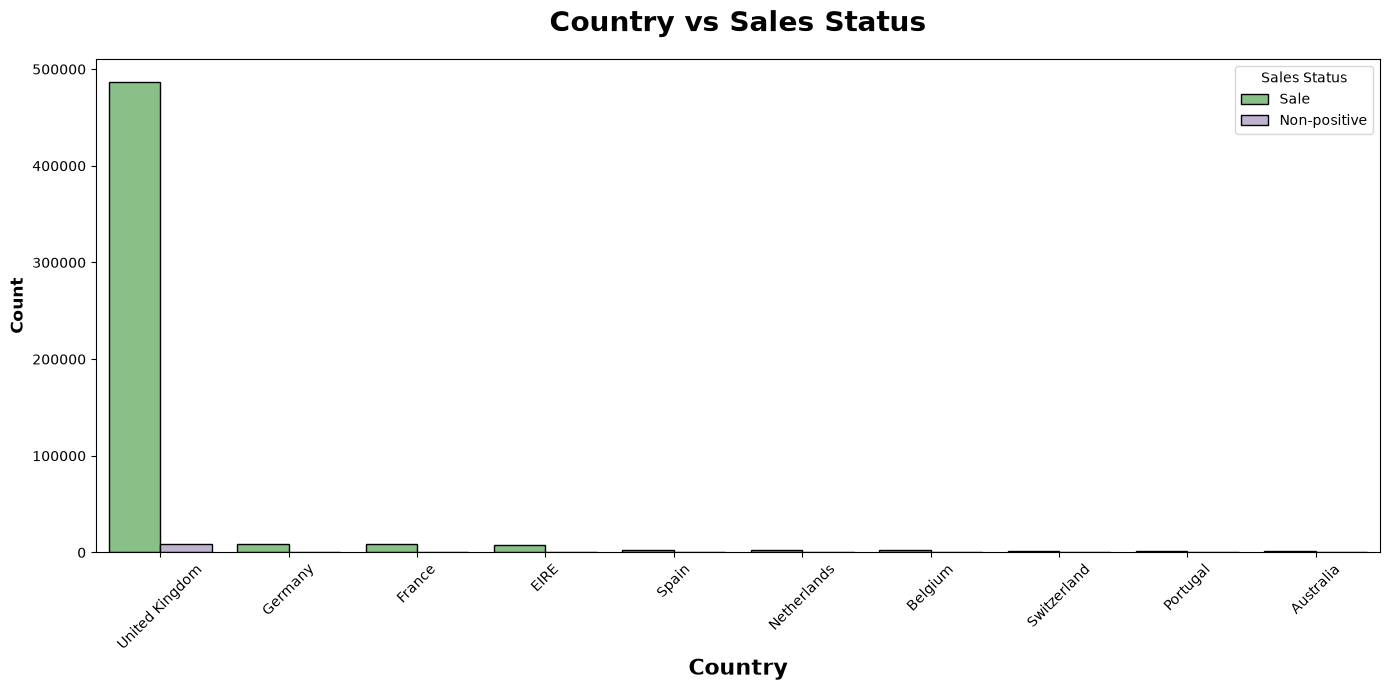

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create Sales Status
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Countries
top_countries = df['Country'].value_counts().head(10).index

df2 = df[df['Country'].isin(top_countries)]

# Create Countplot
plt.figure(figsize=(14, 7))

sns.countplot(
    x="Country",
    hue="SalesStatus",
    data=df2,
    order=top_countries,
    edgecolor="black",
    palette="Accent"
)

plt.title(
    "Country vs Sales Status",
    weight="bold",
    fontsize=20,
    pad=20
)

plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Country", weight="bold", fontsize=16)

plt.xticks(rotation=45)
plt.legend(title="Sales Status", fancybox=True)
plt.tight_layout()
plt.show()

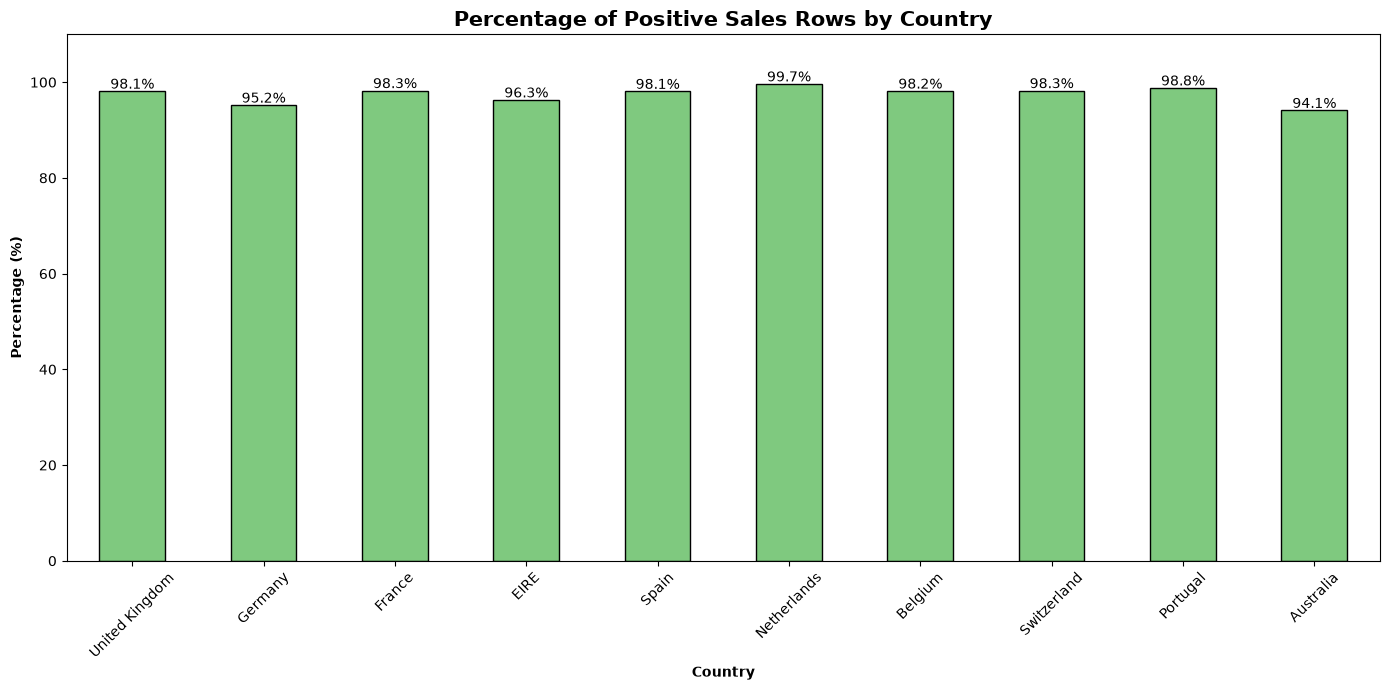

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create Sales Status
df2 = df.copy()

df2['SalesStatus'] = np.where(
    df2['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Calculate percentage of Sale rows by Country
order1 = (
    100 *
    df2[df2['SalesStatus'] == 'Sale']['Country'].value_counts()
    / df2['Country'].value_counts()
).fillna(0)

# Select Top 10 Countries by number of rows
top_countries = df2['Country'].value_counts().head(10).index
order1 = order1.reindex(top_countries)

# Plot
plt.figure(figsize=(14, 7))

order1.plot(
    kind='bar',
    colormap='Accent',
    edgecolor='black'
)

plt.title(
    "Percentage of Positive Sales Rows by Country",
    fontsize=15,
    fontweight='bold'
)

# Add percentage labels
for n in range(len(order1)):
    count = order1.iloc[n]
    plt.text(
        n,
        count + 0.5,
        f'{count:.1f}%',
        ha='center'
    )

plt.xlabel('Country', fontweight='bold')
plt.ylabel('Percentage (%)', fontweight='bold')
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Analysis notes**

A best-selling product by quantity may differ from the product with the highest revenue. Report the metric used, and group sparse or missing product descriptions using an appropriate product identifier such as `StockCode`.

### 4.4 Analyze historical sales trends

In [46]:
#group data by has_job_experience and count case_status
import numpy as np
import pandas as pd

# Create SalesStatus if not already present
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Group data by Country and count SalesStatus percentage
result = (
    df.groupby('Country')['SalesStatus']
    .value_counts(normalize=True)
    .mul(100)
    .to_frame(name='Percentage')
)

display(result)

Percentage
Country              SalesStatus             
Australia            Sale           94.122319
                     Non-positive    5.877681
Austria              Sale           99.251870
                     Non-positive    0.748130
Bahrain              Sale           94.736842
...                                       ...
USA                  Non-positive   38.487973
United Arab Emirates Sale          100.000000
United Kingdom       Sale           98.144822
                     Non-positive    1.855178
Unspecified          Sale          100.000000

[68 rows x 1 columns]

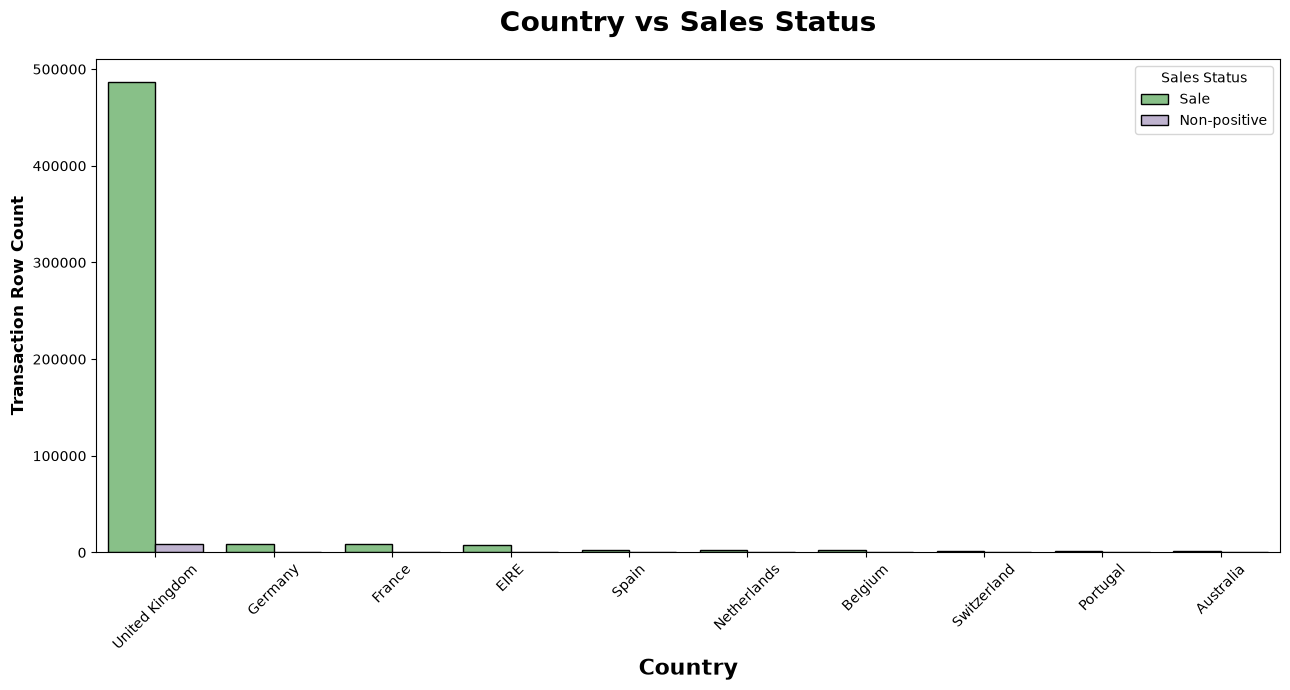

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create Sales Status
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Countries
top_countries = df['Country'].value_counts().head(10).index
df2 = df[df['Country'].isin(top_countries)].copy()

# Create Countplot
plt.figure(figsize=(13, 7))

sns.countplot(
    x="Country",
    hue="SalesStatus",
    data=df2,
    order=top_countries,
    edgecolor="black",
    palette="Accent"
)

plt.title(
    "Country vs Sales Status",
    weight="bold",
    fontsize=20,
    pad=20
)

plt.ylabel("Transaction Row Count", weight="bold", fontsize=12)
plt.xlabel("Country", weight="bold", fontsize=16)

plt.xticks(rotation=45)
plt.legend(title="Sales Status", fancybox=True)
plt.tight_layout()
plt.show()

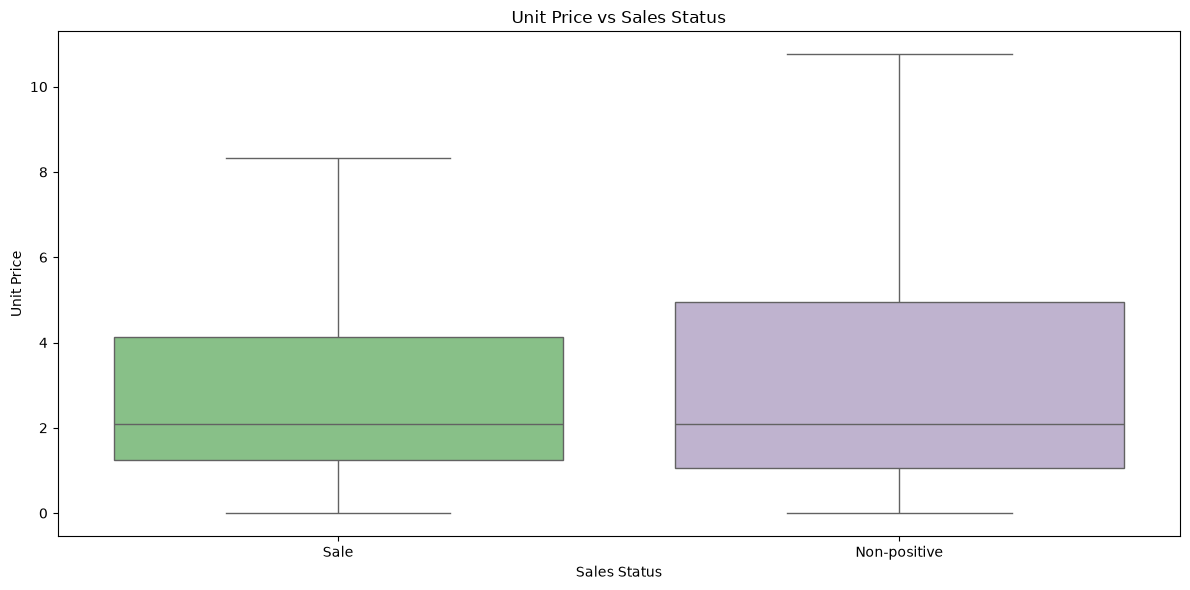

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='SalesStatus',
    y='UnitPrice',
    hue='SalesStatus',
    palette='Accent',
    legend=False,
    showfliers=False
)

plt.title('Unit Price vs Sales Status')
plt.xlabel('Sales Status')
plt.ylabel('Unit Price')
plt.tight_layout()
plt.show()

**Report guidance**

Aggregate transactions by date or month before comparing periods. Check for seasonality and incomplete periods; a trend is descriptive and does not by itself explain why sales changed.

### 4.5 Review returns and cancellations

In [53]:
import pandas as pd
import numpy as np

# Convert StockCode to String
df['StockCode'] = df['StockCode'].astype('string')

# Create Sales Status
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Group data by StockCode and SalesStatus
result = (
    df.groupby('StockCode')['SalesStatus']
    .value_counts(normalize=True)
    .mul(100)
    .to_frame(name='Percentage')
)

display(result)

Percentage
StockCode    SalesStatus             
10002        Sale           98.630137
             Non-positive    1.369863
10080        Sale          100.000000
10120        Sale          100.000000
10123C       Sale           75.000000
...                               ...
gift_0001_20 Sale          100.000000
gift_0001_30 Sale          100.000000
gift_0001_40 Sale          100.000000
gift_0001_50 Sale          100.000000
m            Sale          100.000000

[6500 rows x 1 columns]

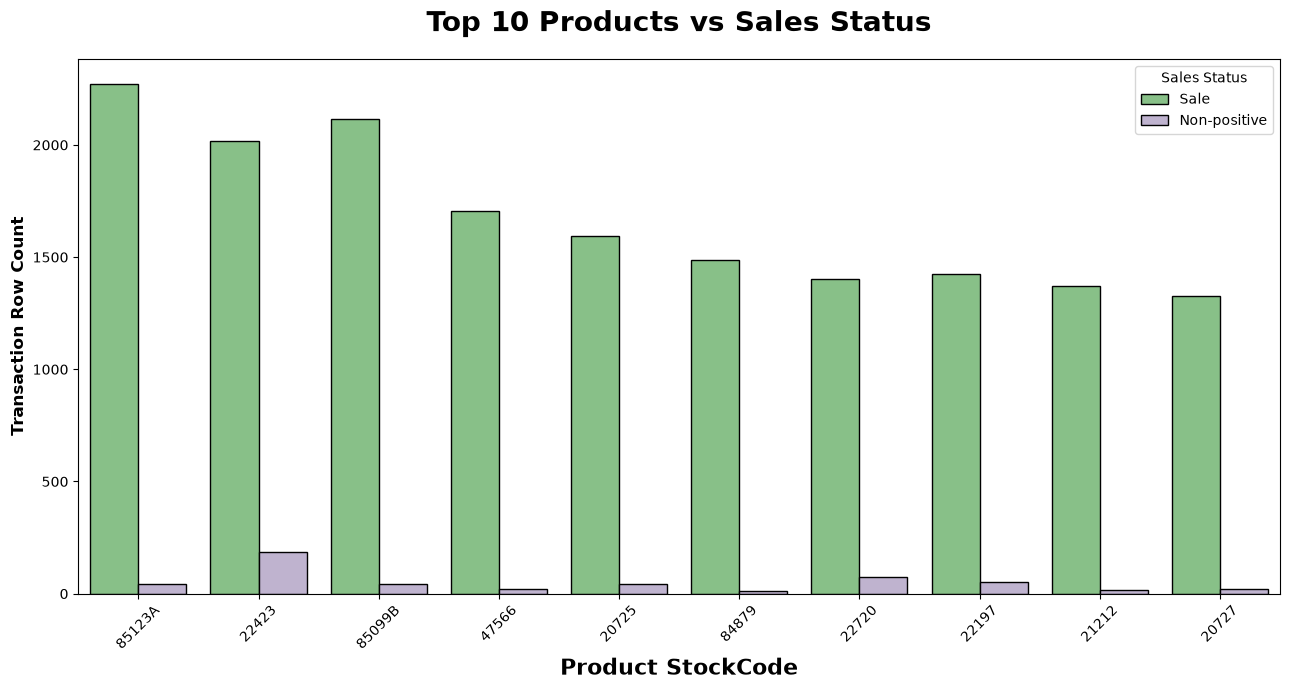

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Convert StockCode to string
df['StockCode'] = df['StockCode'].astype(str)

# Create SalesStatus
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Products
top_products = df['StockCode'].value_counts().head(10).index

df2 = df[df['StockCode'].isin(top_products)].copy()

# Create Countplot
plt.figure(figsize=(13, 7))

sns.countplot(
    x="StockCode",
    hue="SalesStatus",
    data=df2,
    order=top_products,
    edgecolor="black",
    palette="Accent"
)

plt.title(
    "Top 10 Products vs Sales Status",
    weight="bold",
    fontsize=20,
    pad=20
)

plt.ylabel("Transaction Row Count", weight="bold", fontsize=12)
plt.xlabel("Product StockCode", weight="bold", fontsize=16)

plt.xticks(rotation=45)
plt.legend(title="Sales Status", fancybox=True)

plt.tight_layout()
plt.show()

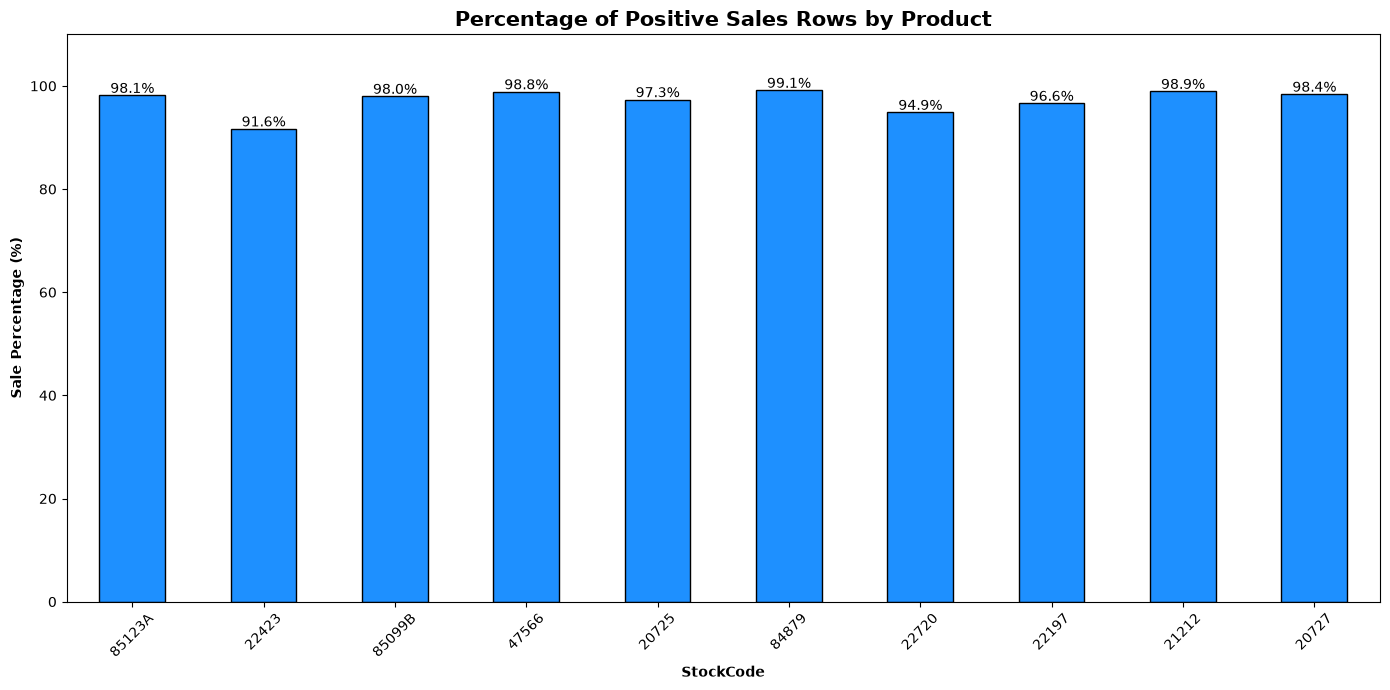

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a fresh copy
df2 = df.copy()

# Convert StockCode to string
df2['StockCode'] = df2['StockCode'].astype('string')

# Create Sales Status
df2['SalesStatus'] = np.where(
    df2['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Products
top_products = df2['StockCode'].value_counts().head(10).index

# Filter Top 10 Products
df2 = df2[df2['StockCode'].isin(top_products)].copy()

# Calculate Sale Percentage
order1 = (
    df2.groupby('StockCode')['SalesStatus']
    .apply(lambda x: (x == 'Sale').mean() * 100)
    .reindex(top_products)
)

# Plot
plt.figure(figsize=(14, 7))

order1.plot(
    kind='bar',
    color='#1E90FF',
    edgecolor='black'
)

plt.title(
    "Percentage of Positive Sales Rows by Product",
    fontsize=15,
    fontweight='bold'
)

# Add Percentage Labels
for n, count in enumerate(order1):
    plt.text(
        n,
        count + 0.5,
        f'{count:.1f}%',
        ha='center'
    )

plt.xlabel('StockCode', fontweight='bold')
plt.ylabel('Sale Percentage (%)', fontweight='bold')
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Report guidance**

Inspect negative quantities and cancellation records separately. A gross-sales metric can include positive quantity and price rows, while a net-revenue metric includes negative return/cancellation lines. State the chosen definition with each KPI.

### 4.6 Detect unusual sales patterns

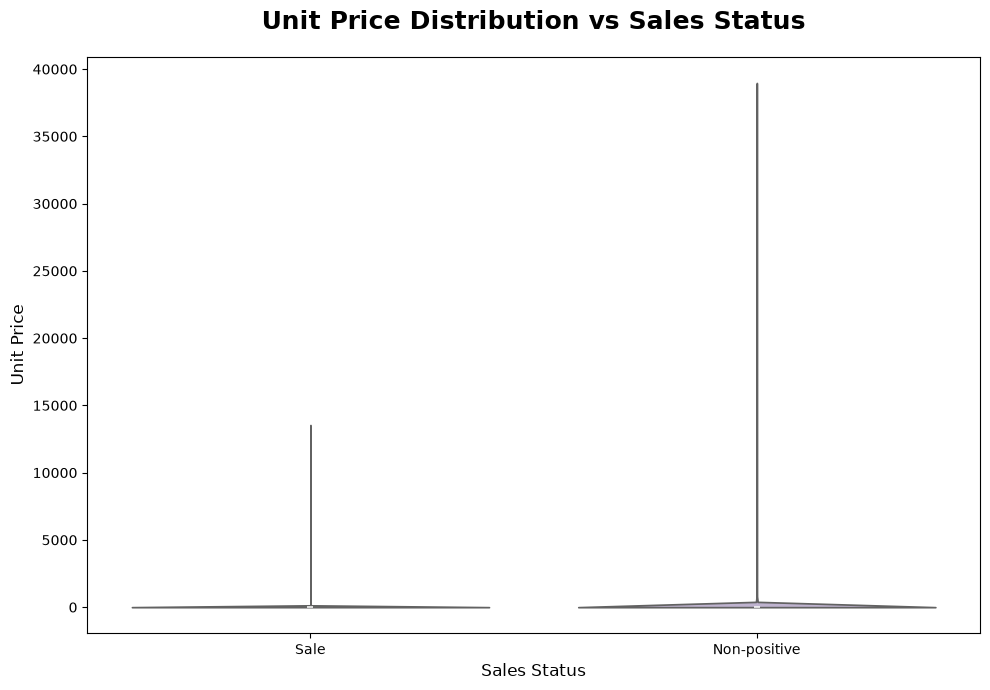

In [59]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create SalesStatus
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Prepare numeric data
df_plot = df[['SalesStatus', 'UnitPrice']].copy()
df_plot['UnitPrice'] = pd.to_numeric(
    df_plot['UnitPrice'],
    errors='coerce'
)

# Remove missing and invalid prices
df_plot = df_plot.dropna()
df_plot = df_plot[df_plot['UnitPrice'] >= 0]

# Create Violin Plot
plt.figure(figsize=(10, 7))

sns.violinplot(
    x='SalesStatus',
    y='UnitPrice',
    data=df_plot,
    hue='SalesStatus',
    palette='Accent',
    legend=False,
    cut=0
)

plt.title(
    "Unit Price Distribution vs Sales Status",
    weight='bold',
    fontsize=18,
    pad=20
)

plt.ylabel("Unit Price", fontsize=12)
plt.xlabel("Sales Status", fontsize=12)

plt.tight_layout()
plt.show()

**Analysis notes**

Compare daily or monthly totals with a historical baseline. Large deviations are potential anomalies to investigate; verify data quality, promotions, holidays, and other context before drawing conclusions.

### 4.7 Analyze revenue and unit price

In [61]:
#group data by unit_of_wage and count the case_status
result = (
    df.groupby('Country')['SalesStatus']
    .value_counts(normalize=True)
    .mul(100)
    .to_frame(name='Percentage')
)

display(result)

Percentage
Country              SalesStatus             
Australia            Sale           94.122319
                     Non-positive    5.877681
Austria              Sale           99.251870
                     Non-positive    0.748130
Bahrain              Sale           94.736842
...                                       ...
USA                  Non-positive   38.487973
United Arab Emirates Sale          100.000000
United Kingdom       Sale           98.144822
                     Non-positive    1.855178
Unspecified          Sale          100.000000

[68 rows x 1 columns]

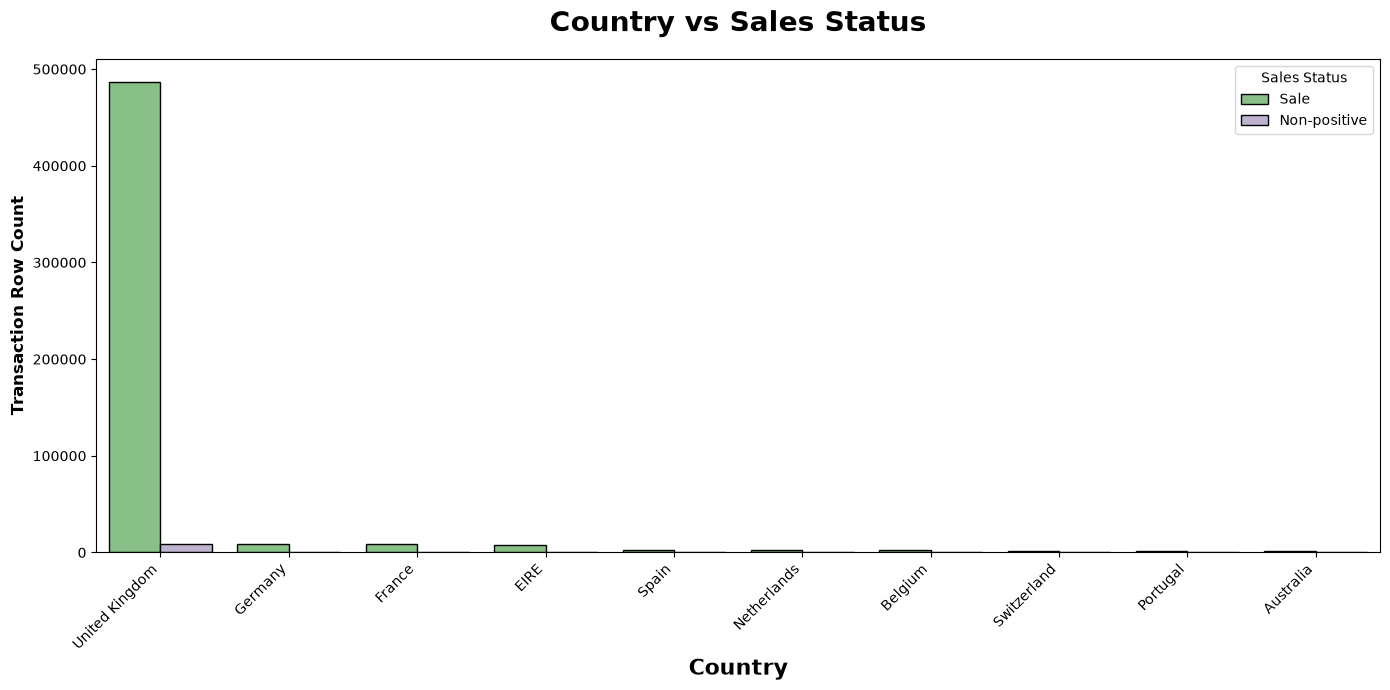

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create SalesStatus
df['SalesStatus'] = np.where(
    df['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Countries
top_countries = df['Country'].value_counts().head(10).index

# Filter Data
df2 = df[df['Country'].isin(top_countries)].copy()

# Create Countplot
plt.figure(figsize=(14, 7))

sns.countplot(
    x='Country',
    hue='SalesStatus',
    data=df2,
    order=top_countries,
    edgecolor='black',
    palette='Accent'
)

plt.title(
    "Country vs Sales Status",
    weight='bold',
    fontsize=20,
    pad=20
)

plt.xlabel('Country', weight='bold', fontsize=16)
plt.ylabel('Transaction Row Count', weight='bold', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.legend(title='Sales Status')

plt.tight_layout()
plt.show()

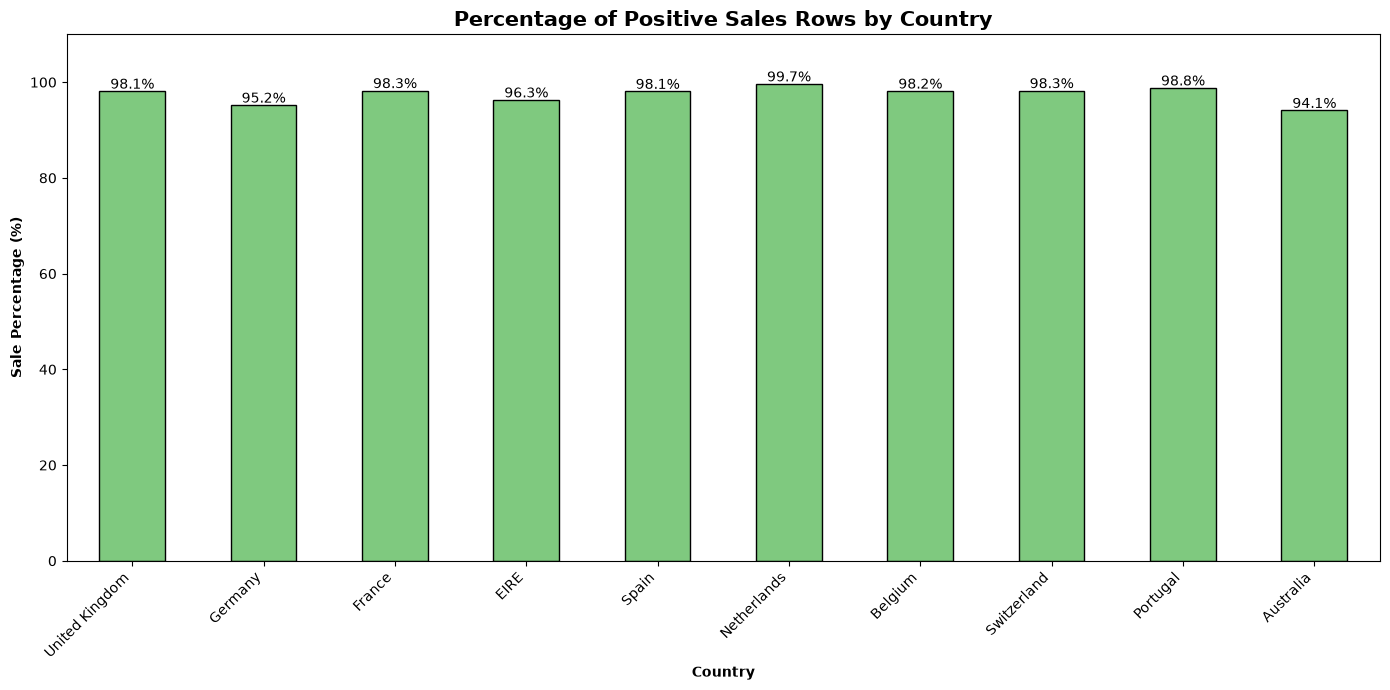

In [65]:
import numpy as np
import matplotlib.pyplot as plt

# Create a fresh copy
df2 = df.copy()

# Create SalesStatus
df2['SalesStatus'] = np.where(
    df2['Quantity'] > 0,
    'Sale',
    'Non-positive'
)

# Select Top 10 Countries
top_countries = df2['Country'].value_counts().head(10).index

# Filter Top 10 Countries
df2 = df2[df2['Country'].isin(top_countries)].copy()

# Calculate Sale Percentage
order1 = (
    df2.groupby('Country')['SalesStatus']
    .apply(lambda x: (x == 'Sale').mean() * 100)
    .reindex(top_countries)
)

# Create Bar Chart
plt.figure(figsize=(14, 7))

order1.plot(
    kind='bar',
    colormap='Accent',
    edgecolor='black'
)

plt.title(
    "Percentage of Positive Sales Rows by Country",
    fontsize=15,
    fontweight='bold'
)

# Add Percentage Labels
for n, count in enumerate(order1):
    plt.text(
        n,
        count + 0.5,
        f'{count:.1f}%',
        ha='center'
    )

plt.xlabel('Country', fontweight='bold')
plt.ylabel('Sale Percentage (%)', fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

**Report guidance**

For Online Retail, calculate line revenue as `Quantity * UnitPrice`. Distinguish total positive-sales revenue from net revenue including returns/cancellations, and report order counts separately from item quantities.

### 4.8 Compare store and city performance

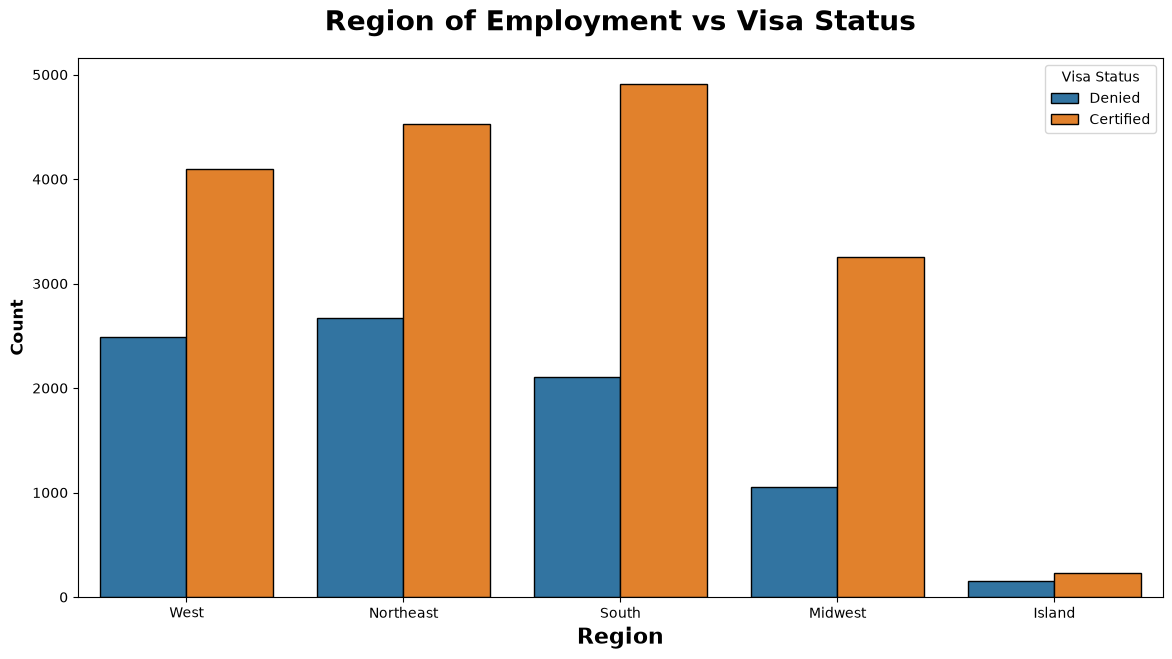

In [ ]:
plt.subplots(figsize=(14,7))
sns.countplot(x="region_of_employment",hue="case_status", data=df,ec='k')
plt.title("Region of Employment vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Region", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.legend(title="Visa Status", fancybox=True)
plt.show()

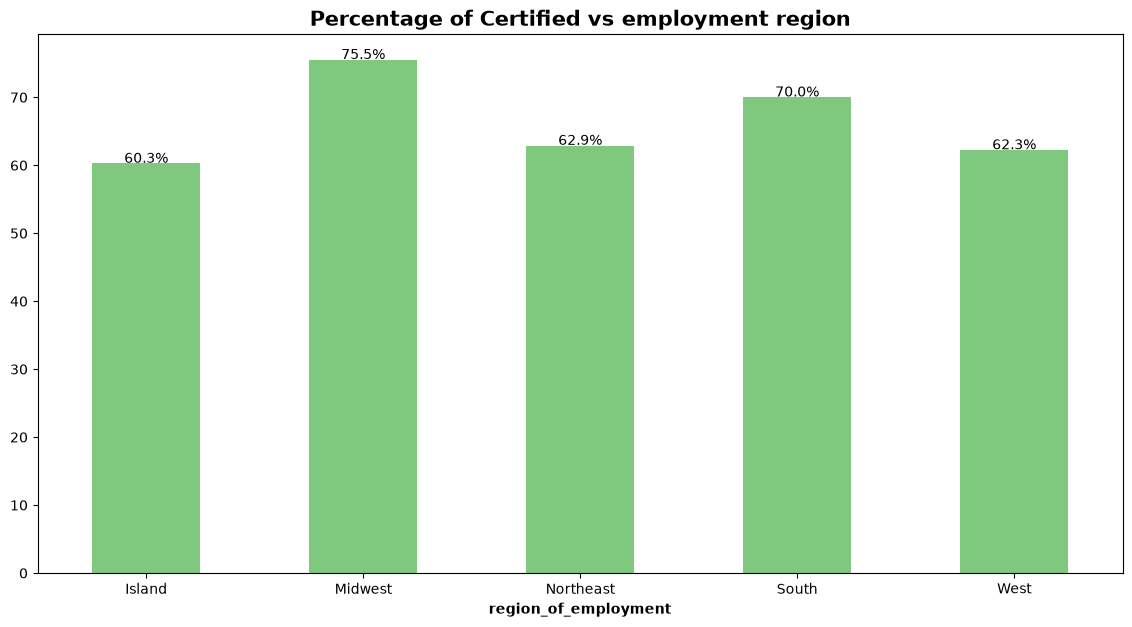

In [ ]:
plt.figure(figsize=[14,7])

(100*df2[df2["case_status"].isin(['Certified'])]['region_of_employment'].value_counts()/df2['region_of_employment'].value_counts()).plot(
    kind='bar',stacked=True , colormap='Accent')
plt.title("Percentage of Certified vs employment region" , fontsize = 15, fontweight ='bold'  )
order1 = (100*df2[df2["case_status"].isin(['Certified'])]['region_of_employment'].value_counts()/df2['region_of_employment'].value_counts())
for n in range(order1.shape[0]):
    count = order1.iloc[n]
    strt='{:0.1f}%'.format(count)
    plt.text(n,count+0.1,strt,ha='center')

plt.xlabel('region_of_employment' , fontweight ='bold')
plt.xticks(rotation=0)
plt.show()

**Report guidance**

Use the location fields available in each source: Online Retail has country, while Store Sales has store and city/state information. Do not infer city or country detail that the dataset does not contain.

### 4.9 Review revenue outliers

In [ ]:
df.groupby('prevailing_wage').case_status.value_counts()

prevailing_wage  case_status
2.1367           Certified      1
2.9561           Denied         1
3.0031           Denied         1
3.3188           Denied         1
3.4889           Certified      1
                               ..
311734.4900      Certified      1
314156.0600      Certified      1
315497.6000      Certified      1
318446.0500      Certified      1
319210.2700      Denied         1
Name: count, Length: 25462, dtype: int64

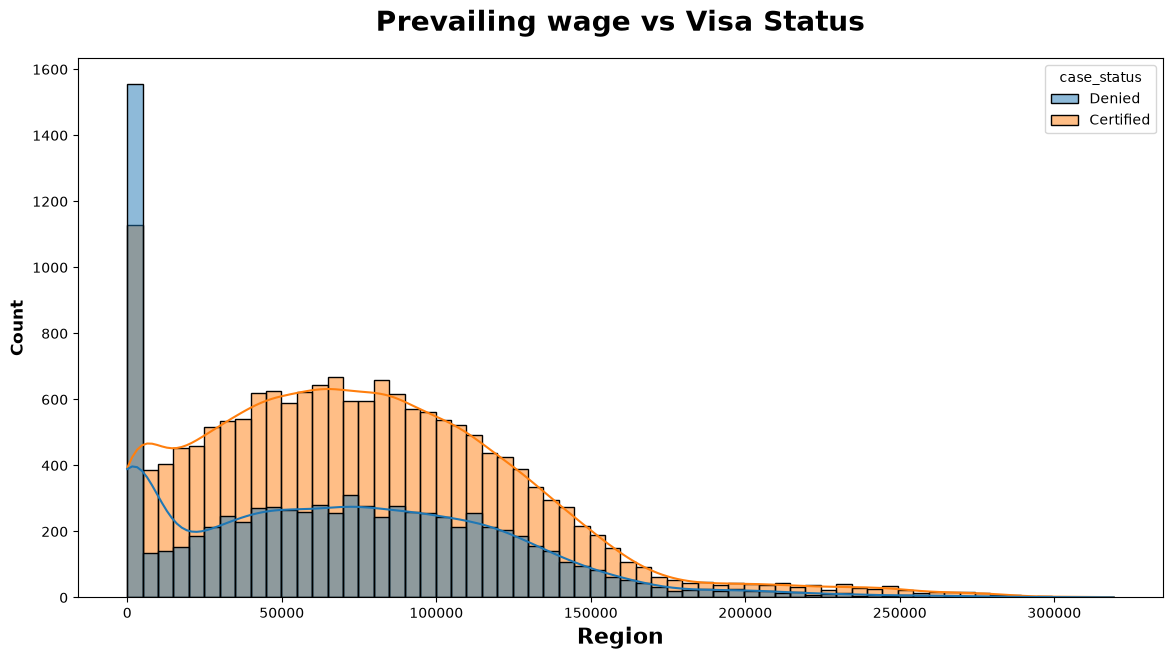

In [ ]:
plt.subplots(figsize=(14,7))
sns.histplot(x="prevailing_wage",hue="case_status", data=df, kde=True)
plt.title("Prevailing wage vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Region", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.show()

**Analysis notes**

Investigate unusually high or low line values and period totals. Check quantity, unit price, returns, and data-entry quality before deciding whether an observation is an error.

#### 4.9.1 Revenue by product

In [ ]:
print('Average Prevailing wage based on Employee education')
df.groupby('education_of_employee')['prevailing_wage'].mean().to_frame().sort_values(by='prevailing_wage',ascending=False)

Average Prevailing wage based on Employee education


,prevailing_wage
education_of_employee,
Master's,78843.057843
Bachelor's,73405.443735
High School,71582.147756
Doctorate,64561.076657


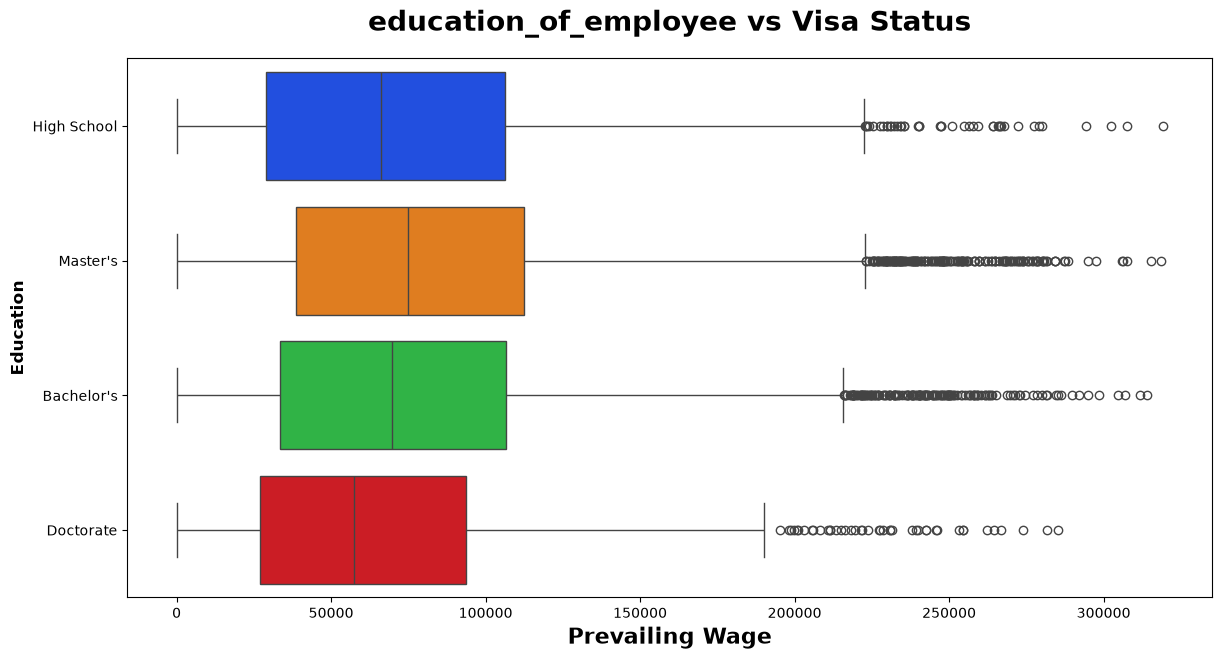

In [ ]:
plt.subplots(figsize=(14,7))
sns.boxplot(y="education_of_employee",x = "prevailing_wage", data=df,palette='bright')
plt.title("education_of_employee vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Prevailing Wage", weight="bold", fontsize=16)
plt.ylabel("Education", weight="bold", fontsize=12)
plt.show()

**Report guidance**

Rank products by both quantity sold and revenue when useful. High quantity does not necessarily mean high revenue; show the measure and currency assumptions explicitly.

#### 4.9.2 Prepare historical data for forecasting

In [ ]:
print('Median Prevailing wage based on Job experience')
df.groupby('has_job_experience')['prevailing_wage'].median().to_frame().sort_values(by='prevailing_wage',ascending=False)

Median Prevailing wage based on Job experience


,prevailing_wage
has_job_experience,
N,72602.290
Y,69033.665


**Report guidance**

Aggregate sales to a regular daily or monthly series, preserve time order, and use the latest dates as a validation set. Compare a baseline forecast with actual values using MAE and RMSE.

#### 4.9.3 Review anomalies across available locations

In [ ]:
print('Average Prevailing wage based on Continent')
df.groupby('continent')['prevailing_wage'].mean().to_frame().sort_values(by='prevailing_wage',ascending=False)

Average Prevailing wage based on Continent


,prevailing_wage
continent,
Asia,79543.021780
Africa,77425.923450
Oceania,75994.276719
North America,68066.319257
South America,60209.575314
Europe,59842.925899


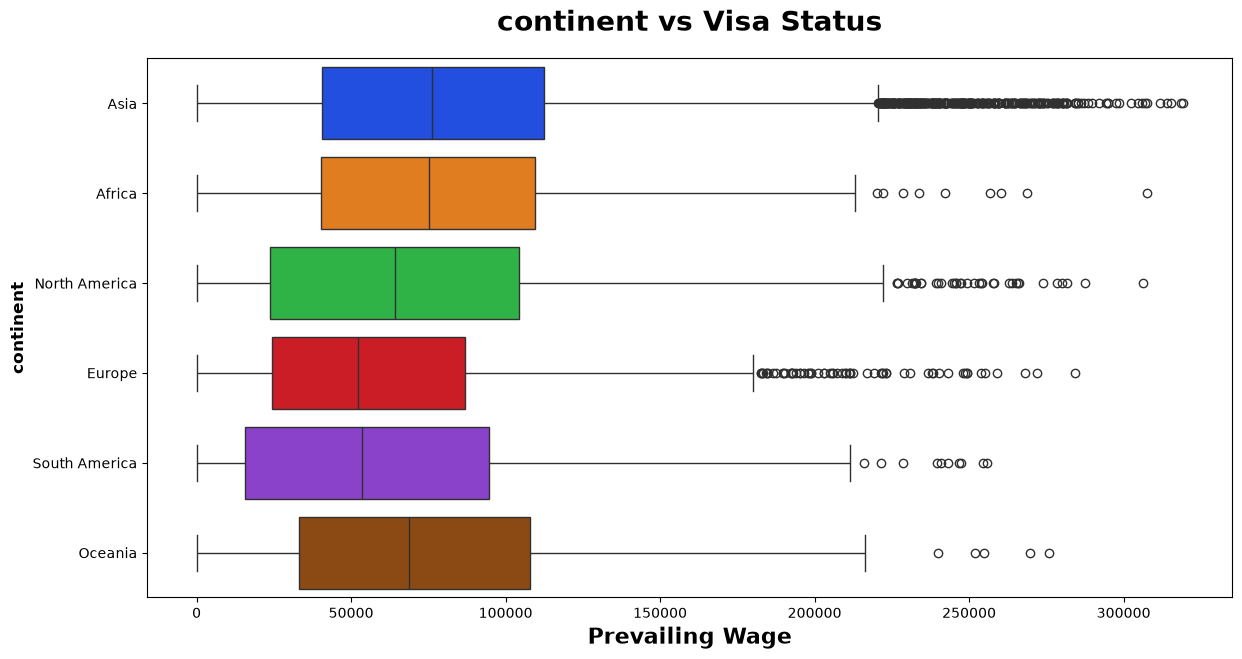

In [ ]:
plt.subplots(figsize=(14,7))
sns.boxplot(y="continent",x = "prevailing_wage", data=df,palette='bright')
plt.title("continent vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("Prevailing Wage", weight="bold", fontsize=16)
plt.ylabel("continent", weight="bold", fontsize=12)
plt.show()

**Report guidance**

Compare anomaly candidates across countries or stores only when the source has those fields and the groups have enough observations. A statistical score is a review signal, not a business explanation.

### 4.10 Check historical date coverage

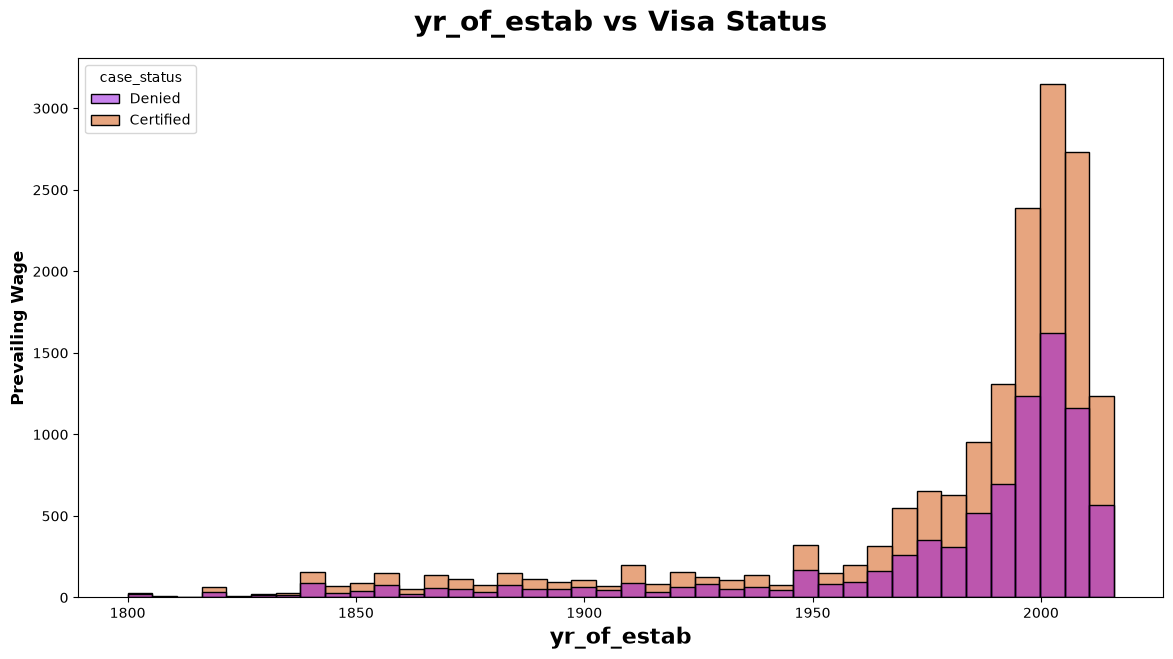

In [ ]:
plt.subplots(figsize=(14,7))
sns.histplot(x = "yr_of_estab", data=df,palette='gnuplot', bins=40, hue='case_status')
plt.title("yr_of_estab vs Visa Status", weight="bold",fontsize=20, pad=20)
plt.xlabel("yr_of_estab", weight="bold", fontsize=16)
plt.ylabel("Prevailing Wage", weight="bold", fontsize=12)
plt.show()

**Report guidance**

Confirm the first and last valid dates, missing periods, and forecast horizon before modeling. Training data must precede validation data to avoid time leakage.

### Final project report

* This notebook introduces the AI Business Intelligence project and its sales-data analysis goals.
* Test best-selling products, monthly sales, country/store comparisons, revenue, forecasting, and anomaly detection with the dataset fields available.
* Online Retail supports country and transaction-revenue analysis; Store Sales supports product-family and store/city sales analysis.
* Keep business metric definitions explicit, especially treatment of returns and whether a value is sales or monetary revenue.
* Existing code cells and stored outputs were not changed as requested.

In [ ]:
########################-------------Feature Engineering and Model Training in Next ipynb------------###########################